Jain's Fairness Index - A measurement of equality in allocation or achieved fairness between clients. 


Cite: A Fairness Perspective on Client Selection and Aggregation Methods for Non-IID Mitigation in Federated Learning: A Survey


Author: Heather Lemon


Date: 24/11/2026

## Pytorch Example with CFAIR-10

In [2]:
import torch
import torchvision
from torchvision.transforms import v2
import torch.nn as nn
import torch.nn.functional as nnFunctional
import torch.optim as optim

import matplotlib.pyplot as plt
import numpy as np
import random

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device(torch.accelerator.current_accelerator()
                      .type if torch.accelerator.is_available() else 'cpu')
print(device, 'device detected')

cuda device detected


In [3]:

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

# train & test datasets and dataloaders from pytorch
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

class CIFAR10CNN(nn.Module):
    """
    param: pytorch neural net module base class  
    """
    def __init__(self, num_classes=10):
        """
        param: num_classes the number of factors/labels/y 
        """
        super(CIFAR10CNN, self).__init__()
        # 2 CNN models with 2 5x5 layers, each with 64 channels
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=5)
        # 2x2 max pool
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 5 * 5, 384)
        self.fc2 = nn.Linear(384, 192)
        self.fc3 = nn.Linear(192, num_classes)

    def forward(self, x):
        """
        @param: x: neural network model
        """
        # flatten images except batch
        x = self.pool(nnFunctional.relu(self.conv1(x)))
        x = self.pool(nnFunctional.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        # apply relu function to network
        x = nnFunctional.relu(self.fc1(x))
        x = nnFunctional.relu(self.fc2(x))
        return self.fc3(x)

if __name__ == "__main__":
    print("\nBuilding CIFAR-10 Model...")
    c_model = CIFAR10CNN()
    c_model.to(device=device)
    # Simulate 1 RGB 32x32 image
    c_input = torch.randn(1, 3, 32, 32)
    c_output = c_model(c_input.to(device))
    print(f"CIFAR-10 Output Shape: {c_output.shape} (Expected: [1, 10])")



Testing CIFAR-10 Model...
CIFAR-10 Output Shape: torch.Size([1, 10]) (Expected: [1, 10])


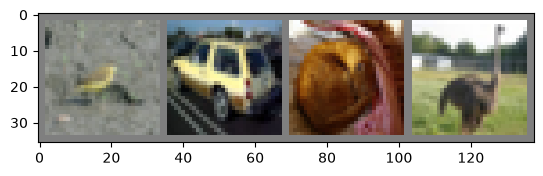

bird  car   cat   bird 


In [4]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    # np.transpose(a=npimg, axes=(0,1,2))
    plt.imshow(np.transpose(a=npimg, axes=(1,2,0)))
    plt.show()

dataiter = iter(trainloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

### Loss function and optimizer

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(CIFAR10CNN.parameters(c_model), lr=0.001, momentum=0.9)

In [6]:
# Pytorch training example
for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data[0].to(device), data[1].to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = c_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')

SAVED_MODEL = './cifar_net.pt'
torch.save(c_model.state_dict(), SAVED_MODEL)
print("saved cifar_net.pt")

[1,  2000] loss: 2.046
[1,  4000] loss: 1.673
[1,  6000] loss: 1.505
[1,  8000] loss: 1.430
[1, 10000] loss: 1.345
[1, 12000] loss: 1.295
[2,  2000] loss: 1.151
[2,  4000] loss: 1.128
[2,  6000] loss: 1.091
[2,  8000] loss: 1.038
[2, 10000] loss: 1.021
[2, 12000] loss: 0.980
Finished Training
saved cifar_net.pt


#### Display Image from Test set

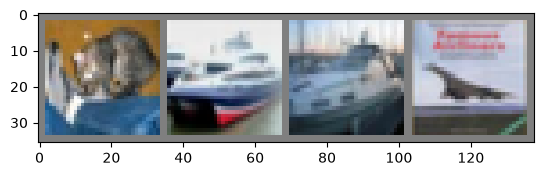

GroundTruth:  cat   ship  ship  plane


In [7]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

In [8]:
csmodel = CIFAR10CNN()
csmodel.load_state_dict(torch.load(SAVED_MODEL, weights_only=True))

<All keys matched successfully>

In [9]:
outputs = csmodel(images)

In [10]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ''.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

Predicted:  cat  ship car  plane


In [11]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = csmodel(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 64 %


In [12]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = csmodel(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 73.7 %
Accuracy for class: car   is 84.7 %
Accuracy for class: bird  is 57.5 %
Accuracy for class: cat   is 43.3 %
Accuracy for class: deer  is 34.6 %
Accuracy for class: dog   is 59.8 %
Accuracy for class: frog  is 80.5 %
Accuracy for class: horse is 63.7 %
Accuracy for class: ship  is 75.5 %
Accuracy for class: truck is 70.6 %
